In [1]:
from pyspark.sql import SparkSession
import time
import math

spark = SparkSession.builder \
    .appName("COVID19_RQ1_MapReduce") \
    .getOrCreate()

sc = spark.sparkContext

In [ ]:
data_path = "Téléchargements/Projet3/covid.csv"

df = spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv(data_path)

In [3]:
data = df.select(
    "countriesAndTerritories",
    "cases_weekly",
    "deaths_weekly"
).dropna()

print("Valid observations:", data.count())

Valid observations: 10647


In [4]:
# Mapper
mapped = data.rdd.map(
    lambda row: (
        row["countriesAndTerritories"],
        (
            1,
            float(row["cases_weekly"]),
            float(row["deaths_weekly"]),
            float(row["cases_weekly"]) ** 2,
            float(row["deaths_weekly"]) ** 2,
            float(row["cases_weekly"]) * float(row["deaths_weekly"])
        )
    )
)
print("Mapped observations:", mapped.count())

Mapped observations: 10647


In [5]:
def reduce_stats(a, b):
    return tuple(x + y for x, y in zip(a, b))
    
reduced = mapped.reduceByKey(reduce_stats)
print("Number of countries:", reduced.count())

Number of countries: 215


In [6]:
def calculate_pearson(stats):
    n, sum_x, sum_y, sum_x2, sum_y2, sum_xy = stats

    variance_x = n * sum_x2 - sum_x ** 2
    variance_y = n * sum_y2 - sum_y ** 2

    if n < 2 or variance_x <= 0 or variance_y <= 0:
        return (n, None)

    numerator = n * sum_xy - sum_x * sum_y
    denominator = math.sqrt(variance_x * variance_y)

    return (n, numerator / denominator)


results = reduced.mapValues(calculate_pearson)

In [9]:
# Final results (head and tail)
final_results = sorted(results.collect(), key=lambda x: x[0])

for country, (n, pearson_r) in final_results[:5]:
    print("{}\t{}\t{}".format(
        country, n,
        pearson_r if pearson_r is not None else "NA"
    ))
print()
for country, (n, pearson_r) in final_results[-5:]:
    print("{}\t{}\t{}".format(
        country, n,
        pearson_r if pearson_r is not None else "NA"
    ))

Afghanistan	58	0.5983417278404136
Albania	49	0.9041163053459342
Algeria	58	0.7212764921189101
Andorra	48	0.3066379401933389
Angola	47	0.8003394898282855

Wallis_and_Futuna	17	NA
Western_Sahara	42	-0.0029736692075012327
Yemen	44	0.9268609766875067
Zambia	47	0.9131633061030852
Zimbabwe	47	0.8097480660046228


In [17]:
# Timer
start_time = time.time()

mapped = data.rdd.map(
    lambda row: (
        row["countriesAndTerritories"],
        (
            1,
            float(row["cases_weekly"]),
            float(row["deaths_weekly"]),
            float(row["cases_weekly"]) ** 2,
            float(row["deaths_weekly"]) ** 2,
            float(row["cases_weekly"]) * float(row["deaths_weekly"])
        )
    )
)

reduced = mapped.reduceByKey(reduce_stats)
results = reduced.mapValues(calculate_pearson)

final_results = sorted(results.collect(), key=lambda x: x[0])

execution_time = time.time() - start_time

print("PySpark execution time: {:.4f} seconds".format(execution_time))

PySpark execution time: 0.4177 seconds


Number of countries displayed: 8


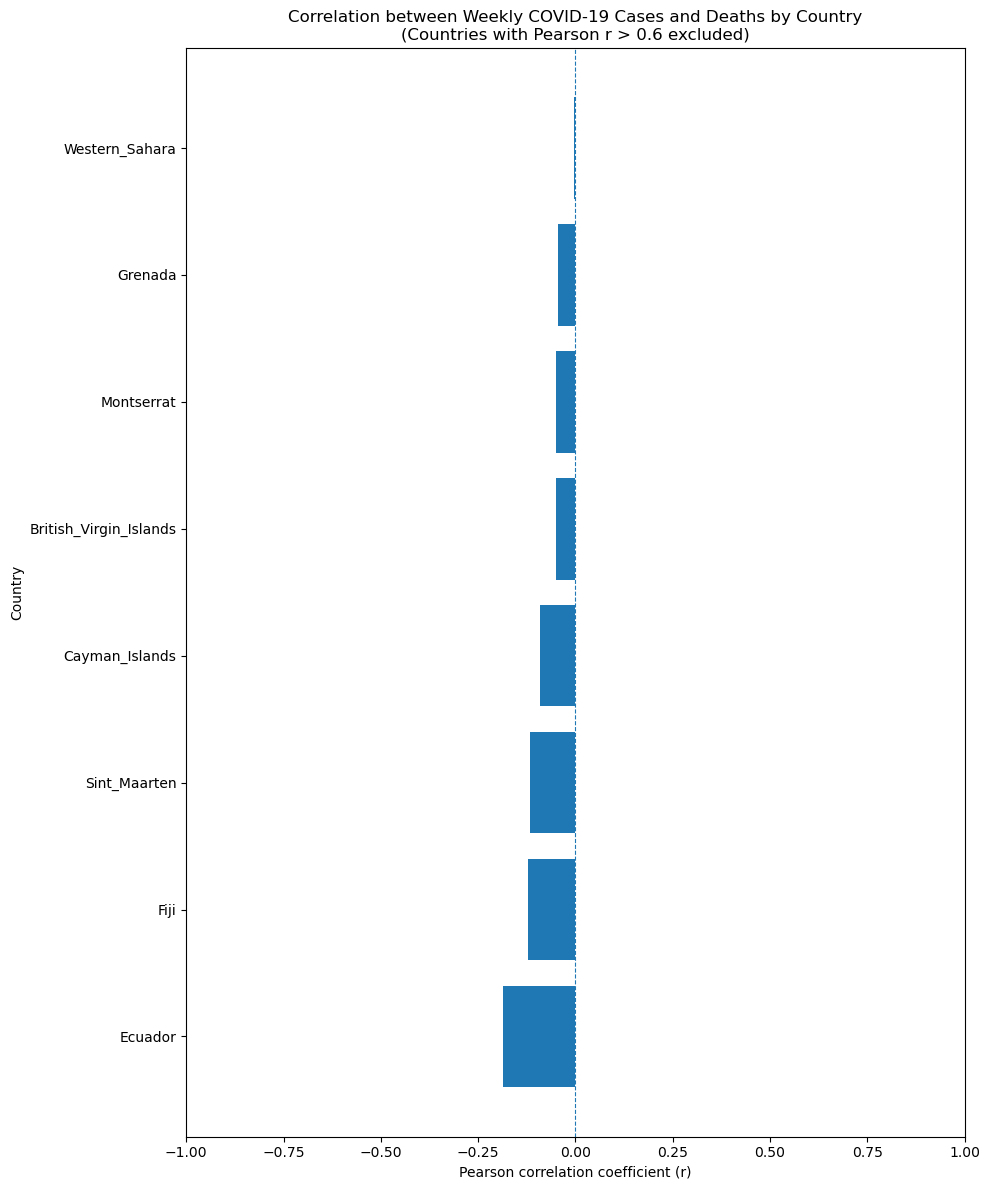

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert PySpark results into a Pandas DataFrame
plot_data = pd.DataFrame(
    final_results,
    columns=["Country", "Statistics"]
)

plot_data["Observations"] = plot_data["Statistics"].apply(lambda x: x[0])
plot_data["Pearson_r"] = plot_data["Statistics"].apply(lambda x: x[1])

# Remove undefined correlations
plot_data = plot_data.dropna(subset=["Pearson_r"])

# Exclude countries with Pearson correlation above 0.6
plot_data = plot_data[plot_data["Pearson_r"] <= 0]

# Sort countries by Pearson correlation
plot_data = plot_data.sort_values("Pearson_r")

print("Number of countries displayed:", len(plot_data))

# Plot
plt.figure(figsize=(10, 12))

plt.barh(
    plot_data["Country"],
    plot_data["Pearson_r"]
)

plt.axvline(x=0, linestyle="--", linewidth=0.8)

plt.xlabel("Pearson correlation coefficient (r)")
plt.ylabel("Country")
plt.title(
    "Correlation between Weekly COVID-19 Cases and Deaths by Country\n"
    "(Countries with Pearson r > 0.6 excluded)"
)

plt.xlim(-1, 1)
plt.tight_layout()
plt.show()